# Notebook 03: Classical SVM benchmark
This initial benchmark compares a majority classifier and linear, RBF and polynomial SVMs.
We use five explicitly chosen stocks for a manageable demonstration, not a representative estimate for the entire S&P 500.
All tickers share date boundaries. Scaling and hyperparameter selection occur inside development folds.
The 2023–2024 evaluation is exploratory: this project has previously inspected that period in other experiments.
Do not tune against these test results or describe them as a new untouched confirmatory test.

### Cell 1: Configure the classical benchmark

Run the documented binary classical benchmark with temporal validation.

In [1]:
from pathlib import Path
import json, hashlib, platform, time
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay)

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'data/processed/SP500_features.csv').exists(), 'Open this notebook from the project folder.'
OUT = ROOT / 'results/stage3'
OUT.mkdir(parents=True, exist_ok=True)
CONFIG = dict(tickers=['AAPL', 'MSFT', 'JPM', 'XOM', 'JNJ'], start='2015-01-01',
              test_start='2023-01-01', end='2025-01-01', max_train_dates=500,
              max_test_dates=200, seed=42, scoring='balanced_accuracy')
features = json.loads((ROOT / 'data/processed/feature_columns.json').read_text())
assert len(features) == 16 and 'target_up' not in features and 'forward_return_1d' not in features
print(CONFIG)

{'tickers': ['AAPL', 'MSFT', 'JPM', 'XOM', 'JNJ'], 'start': '2015-01-01', 'test_start': '2023-01-01', 'end': '2025-01-01', 'max_train_dates': 500, 'max_test_dates': 200, 'seed': 42, 'scoring': 'balanced_accuracy'}


## Load only the selected stocks
Chunked reads avoid holding all 2.4 million feature rows in memory. We recover each label's actual end date from the cleaned price history before filtering feature rows. This matters when intermediate observations are missing.

### Cell 2: Load and validate data

Run the documented binary classical benchmark with temporal validation.

In [2]:
def selected_csv(path, columns):
    parts = []
    for chunk in pd.read_csv(path, usecols=columns, chunksize=200_000, parse_dates=['Date']):
        parts.append(chunk.loc[chunk.Ticker.isin(CONFIG['tickers'])])
    return pd.concat(parts, ignore_index=True).sort_values(['Ticker', 'Date'])

prices = selected_csv(ROOT / 'data/processed/SP500_cleaned_eligible_tickers.csv',
                      ['Ticker', 'Date', 'Close'])
prices['label_end'] = prices.groupby('Ticker')['Date'].shift(-1)
prices['expected_target'] = (prices.groupby('Ticker')['Close'].shift(-1) > prices['Close']).astype(int)
data = selected_csv(ROOT / 'data/processed/SP500_features.csv', ['Ticker', 'Date'] + features + ['target_up'])
data = data.merge(prices[['Ticker', 'Date', 'label_end', 'expected_target']],
                  on=['Ticker', 'Date'], how='left', validate='one_to_one')
assert data.label_end.notna().all()
assert (data.target_up == data.expected_target).all(), 'Labels differ from source prices'
assert np.isfinite(data[features].to_numpy()).all()
assert not data.duplicated(['Ticker', 'Date']).any()
data = data.loc[(data.Date >= CONFIG['start']) & (data.Date < CONFIG['end'])].copy()
print('Available rows:', len(data))

Available rows: 12580


## Freeze the sampling and split protocol
Select evenly spaced observed dates without looking at outcomes; retain all selected tickers available on those dates. Use at most 500 development dates and 200 evaluation dates. Purge labels reaching the next period. No random row splitting is used.

### Cell 3: Define temporal splits

Run the documented binary classical benchmark with temporal validation.

In [3]:
cut = pd.Timestamp(CONFIG['test_start'])
end = pd.Timestamp(CONFIG['end'])
train_pool = data.loc[(data.Date < cut) & (data.label_end < cut)]
test_pool = data.loc[(data.Date >= cut) & (data.label_end < end)]
def sample_dates(frame, maximum):
    dates = np.sort(frame.Date.unique())
    chosen = dates[np.linspace(0, len(dates)-1, min(maximum, len(dates)), dtype=int)]
    return frame.loc[frame.Date.isin(chosen)].sort_values(['Date', 'Ticker']).reset_index(drop=True)
train = sample_dates(train_pool, CONFIG['max_train_dates'])
test = sample_dates(test_pool, CONFIG['max_test_dates'])
X, y = train[features], train.target_up
Xt, yt = test[features], test.target_up
assert train.label_end.max() < test.Date.min()
assert set(train.Date).isdisjoint(test.Date)
assert y.nunique() == yt.nunique() == 2

dates = np.sort(train.Date.unique())
folds, fold_rows = [], []
for number, (a, b) in enumerate(TimeSeriesSplit(n_splits=3, gap=1).split(dates), 1):
    validation_start = pd.Timestamp(dates[b[0]])
    tr = np.flatnonzero(train.Date.isin(dates[a]) & (train.label_end < validation_start))
    va = np.flatnonzero(train.Date.isin(dates[b]))
    assert train.iloc[tr].label_end.max() < train.iloc[va].Date.min()
    assert set(train.iloc[tr].Date).isdisjoint(train.iloc[va].Date)
    assert train.iloc[tr].target_up.nunique() == train.iloc[va].target_up.nunique() == 2
    folds.append((tr, va))
    fold_rows.append(dict(fold=number, train_rows=len(tr), validation_rows=len(va),
                          train_end=str(train.iloc[tr].Date.max().date()),
                          validation_start=str(validation_start.date())))
fold_table = pd.DataFrame(fold_rows)
display(fold_table)
split_table = pd.DataFrame([dict(split=name, rows=len(frame), stocks=frame.Ticker.nunique(),
    start=str(frame.Date.min().date()), end=str(frame.Date.max().date()), up_fraction=frame.target_up.mean())
    for name, frame in [('development', train), ('evaluation', test)]])
display(split_table)
print('Temporal, label and feature checks passed.')

,fold,train_rows,validation_rows,train_end,validation_start
0,1,620,625,2016-12-19,2017-01-03
1,2,1245,625,2018-12-20,2019-01-04
2,3,1870,625,2020-12-21,2021-01-05


,split,rows,stocks,start,end,up_fraction
0,development,2500,5,2015-01-02,2022-12-29,0.498
1,evaluation,1000,5,2023-01-03,2024-12-30,0.527


Temporal, label and feature checks passed.


## Tune models using development folds only
Each SVM includes its own scaler inside the search pipeline. The scaler is refitted separately in each fold. All SVMs use balanced class weights and the same C grid. Test data never enters the search.

### Cell 4: Configure models and search

Run the documented binary classical benchmark with temporal validation.

In [4]:
candidates = {
    'dummy': (DummyClassifier(strategy='most_frequent'), {}),
    'linear': (SVC(kernel='linear', class_weight='balanced'), {'model__C': [0.1, 1, 10]}),
    'rbf': (SVC(kernel='rbf', class_weight='balanced'), {'model__C': [0.1, 1, 10], 'model__gamma': ['scale', 0.01, 0.1]}),
    'polynomial': (SVC(kernel='poly', class_weight='balanced'), {'model__C': [0.1, 1, 10], 'model__degree': [2, 3], 'model__gamma': ['scale']})
}
models, records, cv_tables = {}, [], []
for name, (estimator, grid) in candidates.items():
    pipe = Pipeline([('scale', StandardScaler()), ('model', estimator)])
    search = GridSearchCV(pipe, grid, cv=folds, scoring=CONFIG['scoring'], n_jobs=1,
                          error_score='raise', return_train_score=False)
    started = time.perf_counter()
    search.fit(X, y)
    elapsed = time.perf_counter() - started
    models[name] = search.best_estimator_
    table = pd.DataFrame(search.cv_results_)
    table.insert(0, 'model_name', name)
    cv_tables.append(table)
    records.append(dict(model=name, cv_balanced_accuracy=search.best_score_,
                        tuning_and_refit_seconds=elapsed, parameters=json.dumps(search.best_params_)))
selection = pd.DataFrame(records).set_index('model')
display(selection)

,cv_balanced_accuracy,tuning_and_refit_seconds,parameters
model,,,
dummy,0.500000,0.049931,{}
linear,0.498788,1.534918,"{""model__C"": 1}"
rbf,0.505810,3.013828,"{""model__C"": 0.1, ""model__gamma"": ""scale""}"
polynomial,0.513066,2.008683,"{""model__C"": 10, ""model__degree"": 3, ""model__g..."


## Evaluate the frozen models
Report all prespecified baselines. ROC-AUC uses decision scores; average precision is the reported PR summary. Rows are correlated within market dates and stocks, so these descriptive results are not significance tests.

### Cell 5: Tune and evaluate classical models

Run the documented binary classical benchmark with temporal validation.

In [5]:
metrics, predictions = [], test[['Ticker','Date','target_up']].copy()
for name, model in models.items():
    started = time.perf_counter()
    pred = model.predict(Xt)
    score = model.decision_function(Xt) if hasattr(model, 'decision_function') else model.predict_proba(Xt)[:, 1]
    metrics.append(dict(model=name, accuracy=accuracy_score(yt,pred),
        balanced_accuracy=balanced_accuracy_score(yt,pred), precision=precision_score(yt,pred,zero_division=0),
        recall=recall_score(yt,pred,zero_division=0), f1=f1_score(yt,pred,zero_division=0),
        roc_auc=roc_auc_score(yt,score), average_precision=average_precision_score(yt,score),
        prediction_seconds=time.perf_counter()-started))
    predictions[name+'_prediction'] = pred
    predictions[name+'_score'] = score
metrics = pd.DataFrame(metrics).set_index('model').join(selection)
assert np.isfinite(metrics[['accuracy','balanced_accuracy','roc_auc']].to_numpy()).all()
display(metrics.round(4))

,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision,prediction_seconds,cv_balanced_accuracy,tuning_and_refit_seconds,parameters
model,,,,,,,,,,,
dummy,0.473,0.5000,0.0000,0.0000,0.0000,0.5000,0.5270,0.0168,0.5000,0.0499,{}
linear,0.504,0.5105,0.5407,0.3909,0.4537,0.5204,0.5283,0.0776,0.4988,1.5349,"{""model__C"": 1}"
rbf,0.517,0.5198,0.5489,0.4687,0.5056,0.5227,0.5295,0.3300,0.5058,3.0138,"{""model__C"": 0.1, ""model__gamma"": ""scale""}"
polynomial,0.485,0.4830,0.5112,0.5199,0.5155,0.4789,0.5062,0.0754,0.5131,2.0087,"{""model__C"": 10, ""model__degree"": 3, ""model__g..."


## Visual diagnostics
These charts show the actual sampled partitions, class proportions, confusion matrices and measured runtime. No model selection is performed from these figures.

### Cell 6: Plot binary results

Run the documented binary classical benchmark with temporal validation.

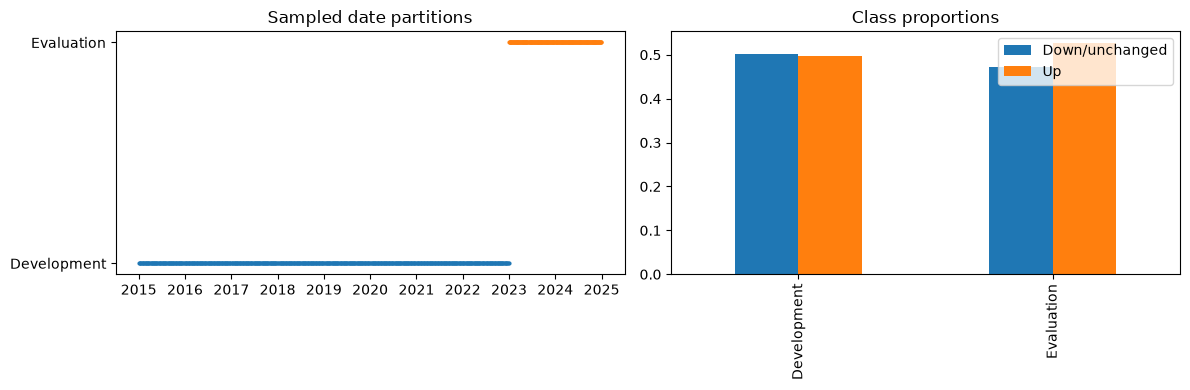

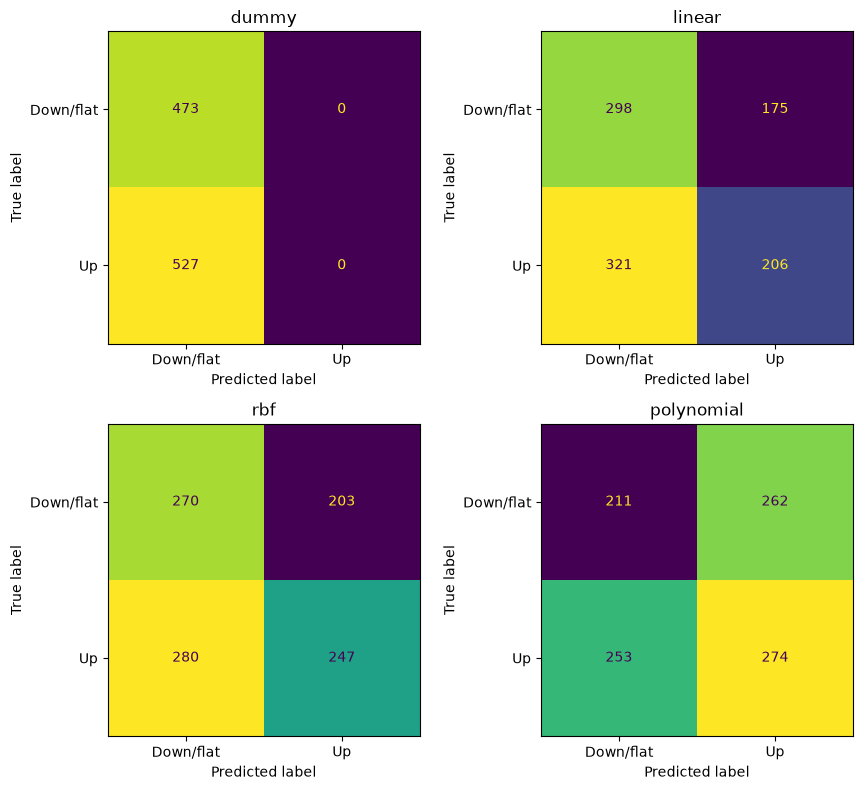

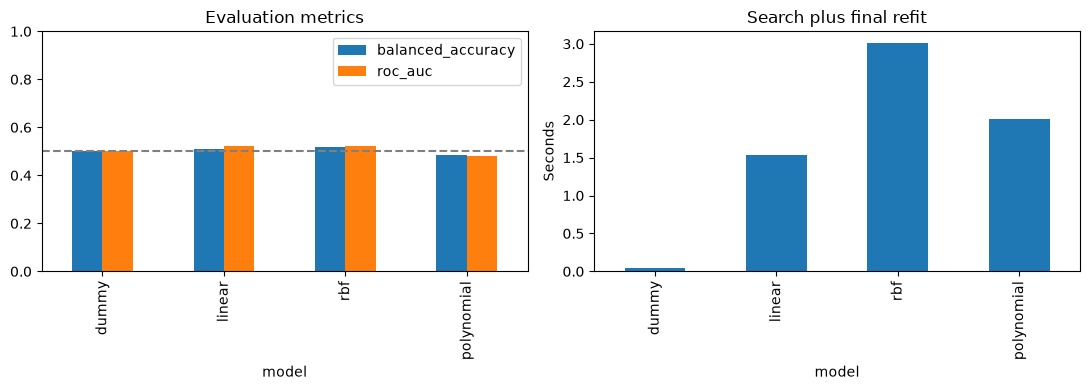

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, (name, frame) in enumerate([('development',train),('evaluation',test)]):
    axes[0].scatter(frame.Date.unique(), np.full(frame.Date.nunique(),i), s=4, label=name)
axes[0].set_yticks([0,1], ['Development','Evaluation'])
axes[0].set_title('Sampled date partitions')
pd.DataFrame({name: frame.target_up.value_counts(normalize=True).reindex([0,1])
    for name,frame in [('Development',train),('Evaluation',test)]}).T.plot.bar(ax=axes[1])
axes[1].set_title('Class proportions'); axes[1].legend(['Down/unchanged','Up'])
fig.tight_layout(); fig.savefig(OUT/'splits_and_balance.png', dpi=150); plt.show()
fig, axes = plt.subplots(2,2,figsize=(9,8))
for ax,name in zip(axes.ravel(),models):
    ConfusionMatrixDisplay(confusion_matrix(yt,predictions[name+'_prediction']),display_labels=['Down/flat','Up']).plot(ax=ax,colorbar=False)
    ax.set_title(name)
fig.tight_layout(); fig.savefig(OUT/'confusion_matrices.png',dpi=150); plt.show()
fig,axes=plt.subplots(1,2,figsize=(11,4))
metrics[['balanced_accuracy','roc_auc']].plot.bar(ax=axes[0]); axes[0].axhline(0.5,color='gray',linestyle='--')
axes[0].set_ylim(0,1); axes[0].set_title('Evaluation metrics')
metrics.tuning_and_refit_seconds.plot.bar(ax=axes[1]); axes[1].set_ylabel('Seconds'); axes[1].set_title('Search plus final refit')
fig.tight_layout(); fig.savefig(OUT/'performance_and_runtime.png',dpi=150); plt.show()

### Cell 7: Save binary evidence

Run the documented binary classical benchmark with temporal validation.

In [7]:
metrics.to_csv(OUT/'metrics.csv')
predictions.to_csv(OUT/'predictions.csv',index=False)
pd.concat(cv_tables,ignore_index=True).to_csv(OUT/'cv_results.csv',index=False)
fold_table.to_csv(OUT/'folds.csv',index=False)
split_table.to_csv(OUT/'splits.csv',index=False)
def sha256(path):
    digest=hashlib.sha256()
    with path.open('rb') as handle:
        for block in iter(lambda: handle.read(1024*1024), b''):
            digest.update(block)
    return digest.hexdigest()
metadata=dict(config=CONFIG, features=features, python=platform.python_version(),
    packages={p:version(p) for p in ['numpy','pandas','scikit-learn','matplotlib','nbclient','nbformat']},
    input_sha256={p:sha256(ROOT/'data/processed'/p) for p in ['SP500_features.csv','feature_columns.json','SP500_cleaned_eligible_tickers.csv']})
(OUT/'metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('Stage 3 completed. Results:',OUT)

Stage 3 completed. Results: E:\Quantum Project\results\stage3


## Interpretation and limitations
This is a five-stock, 16-feature, bounded classical benchmark. It does not establish performance across all 372 stocks. The selected stock universe and long-history eligibility can introduce survivorship bias. Price adjustment remains unverified; the earlier HUBB imputation is not source-verified. The test period is exploratory, and no financial profitability or statistical significance is claimed.

The next stage will fit PCA and bounded quantum input mappings on training data, then compare classical and quantum models on identical observations and representations. No QSVM, noise or hardware experiment is part of this stage.

### Load the binary and three-class extension

Use a prespecified label policy and a larger chronological sample, separate from legacy results.

In [8]:
import runpy
from pathlib import Path
EXT_ROOT = Path.cwd()
if EXT_ROOT.name == 'notebooks': EXT_ROOT = EXT_ROOT.parent
extension = runpy.run_path(str(EXT_ROOT / 'experiments/multiclass_extension.py'))
extension['self_test']()
print(extension['CONFIG'])

{'tickers': ['AAPL', 'MSFT', 'JPM', 'XOM', 'JNJ'], 'train_dates': 200, 'validation_dates': 80, 'evaluation_dates': 100, 'threshold': 0.0025, 'start': '2015-01-01', 'validation_start': '2021-01-01', 'evaluation_start': '2023-01-01', 'end': '2025-01-01', 'seed': 42}


### Run both classification tasks

Tune each task on validation only and report every planned configuration on the same evaluation keys.

In [9]:
extension_metrics, extension_support = extension['run'](EXT_ROOT, 3)
display(extension_metrics[['task','dimension','model','balanced_accuracy','macro_f1']])
display(extension_support)
print('Three-class labels: 0 DOWN, 1 NEUTRAL, 2 UP. Binary labels remain 0 DOWN/flat, 1 UP.')

,task,dimension,model,balanced_accuracy,macro_f1
0,binary,16,dummy,0.500000,0.360614
1,binary,16,linear,0.493835,0.485998
2,binary,16,rbf,0.506360,0.504094
3,binary,16,polynomial,0.510931,0.499800
4,three_class,16,dummy,0.333333,0.206897
5,three_class,16,linear,0.306479,0.260340
6,three_class,16,rbf,0.341389,0.302340
7,three_class,16,polynomial,0.359877,0.292714


,split,task,label,rows,dates
0,train,binary,0,506,200
1,train,binary,1,494,200
2,train,three_class,0,395,200
3,train,three_class,1,194,200
4,train,three_class,2,411,200
5,validation,binary,0,183,80
6,validation,binary,1,217,80
7,validation,three_class,0,160,80
8,validation,three_class,1,55,80
9,validation,three_class,2,185,80


Three-class labels: 0 DOWN, 1 NEUTRAL, 2 UP. Binary labels remain 0 DOWN/flat, 1 UP.


## Extension interpretation

Results belong to separate binary and three-class tasks. Raw scores across tasks do not measure the same difficulty. The larger 2023–2024 sample is still exploratory and correlated, not a fresh holdout. Thresholds were fixed before this run, not optimized. Macro-F1 and balanced accuracy summarize classification; no multiclass AUC is inferred from uncalibrated SVC scores. Stage 3 full-feature models and Stage 4 reduced-input models are separate experiment families. Kernel construction is label-independent and reused across tasks when preprocessing is identical.